# humor-me: decisions and the experiments behind them

**One place for every decision.** The written log is [`docs/decisions.md`](../docs/decisions.md);
this notebook is its **evidence**: each decision that rests on an experiment has a section here
that re-runs it, shows the table/figure, and **checks the claim** the decision depends on.

**How to use it**
- Open it and read: results load from `reports/metrics/*.json` (cached by parameters), so
  nothing recomputes unless you ask.
- Change a parameter in a cell → that experiment recomputes (seconds to ~3 min) and the cache updates.
- `RERUN = True` below recomputes everything (~6 min).
- Every claim has a **✅ / ❌ check** under it. If a code or parameter change flips one to ❌,
  the decision it backs needs revisiting.
- Before committing: `python scripts/run_notebook.py` (restart + run all, clean metadata).

Rules: logic lives in `sim/` and `pipeline/` functions; cells only call, display and check.
Vocabulary: [glossary](../docs/wiki/glossary.md).

In [1]:
import os, re, sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from IPython.display import Markdown, display
from sim import evaluate_env, evaluate_policies, evaluate_shift
from sim.cache import load, run_or_load

RERUN = False  # True = recompute every experiment (~6 min)

def show(md_text):
    display(Markdown(md_text))

def check(claim, ok):
    show(f"{'✅' if ok else '❌'} **{claim}**")
    return ok

## Index: every decision

Parsed live from `docs/decisions.md`, so it can't go stale. **Evidence** points at the section
below that re-runs it; "rationale" means the decision rests on reasoning or constraints, not an
experiment (the reasoning is in the log).

In [2]:
EVIDENCE = {  # title fragment in decisions.md -> section in this notebook
    "S4: Gemini directly on whole sets": "Exp 1 Bit segmentation",
    "Bit = smallest standalone unit": "Exp 1 Bit segmentation",
    "Pause the transcript pipeline": "Exp 2 rJokes prep",
    "picks a mode per bit": "Exp 3 Per-joke vs per-bit",
    "Director policy: LinUCB": "Exp 4 Policies × priors",
    "Keep the director's features": "Exp 5 Mid-set shift",
    "Keep 8-bit sets": "Exp 6 Set length vs shift",
}
rows = []
for date, title in re.findall(r"^## (\d{4}-\d{2}-\d{2}) — (.+)$", Path("docs/decisions.md").read_text(encoding="utf-8"), re.M):
    ev = next((v for k, v in EVIDENCE.items() if k in title), "rationale")
    rows.append(f"| {len(rows) + 1} | {date} | {title} | {ev} |")
show("| # | Date | Decision | Evidence |\n|---|---|---|---|\n" + "\n".join(rows))

| # | Date | Decision | Evidence |
|---|---|---|---|
| 1 | 2026-10-20 | Audio-only realtime loop | rationale |
| 2 | 2026-10-20 | Per-joke laughter is the reward; episode rating is the outcome | rationale |
| 3 | 2026-10-20 | Contextual bandit over HumorGen persona modes, fixed core identity | rationale |
| 4 | 2026-10-20 | LLM-as-judge first, learned reward model later | rationale |
| 5 | 2026-10-20 | Data sources | rationale |
| 6 | 2026-10-20 | Research framing | rationale |
| 7 | 2026-10-20 | M1 = Dec 15 (RL course final project, school demo) | rationale |
| 8 | 2026-10-20 | Context = three operator-set features, not one venue label | rationale |
| 9 | 2026-10-20 | Teens = stricter safety filter (hard rule) | rationale |
| 10 | 2026-10-20 | Model output = next bit, conditioned on room state | rationale |
| 11 | 2026-10-20 | Transcripts are for structure + reward, never as imitation text | rationale |
| 12 | 2026-10-20 | Laugh labels: lexicon-mapped levels, binary primary | rationale |
| 13 | 2026-10-20 | Opener/closer are positions, not bit types | rationale |
| 14 | 2026-10-20 | Density gate for laugh labels; Birbiglia replaces Bamford in held-out | rationale |
| 15 | 2026-10-21 | Applause alone is not a laugh | rationale |
| 16 | 2026-10-21 | Two datasets, split logically at the output | rationale |
| 17 | 2026-10-21 | Callbacks are first-class: hooks in set memory, callback(k) planner action | rationale |
| 18 | 2026-10-21 | Laugh predictor trains on lines, not beats | rationale |
| 19 | 2026-10-21 | Gemini (free tier) for S4–S5, with minimal excerpts | rationale |
| 20 | 2026-10-21 | S4: Gemini directly on whole sets (supersedes "minimal excerpts" above) | Exp 1 Bit segmentation |
| 21 | 2026-10-21 | Bit = smallest standalone unit; same-topic bits form a thread | Exp 1 Bit segmentation |
| 22 | 2026-10-26 | Pause the transcript pipeline; rJokes + simulator first | Exp 2 rJokes prep |
| 23 | 2026-10-26 | Long-form sets are planned hierarchically, not generated in one pass | rationale |
| 24 | 2026-10-26 | Northeastern Explorer for GPU work; laptop for everything else | rationale |
| 25 | 2026-10-27 | The director picks a mode per bit, not per joke | Exp 3 Per-joke vs per-bit |
| 26 | 2026-10-27 | Director policy: LinUCB with a uniform prior | Exp 4 Policies × priors |
| 27 | 2026-10-28 | Keep the director's features; within-show adaptation needs show state | Exp 5 Mid-set shift |
| 28 | 2026-10-28 | Keep 8-bit sets; longer sets don't let the director read a turn | Exp 6 Set length vs shift |

## Exp 1 Bit segmentation on stand-up transcripts (2026-10-21)

**Decision:** S4 asks Gemini for bit boundaries on whole sets; a bit = smallest standalone stretch.
**Where it fits:** the transcript pipeline that gives the report its "how a comedian builds a set"
evidence ([stand-up structure](../docs/wiki/standup-structure.md)). Paused since 2026-10-26.
**Question:** does an LLM find bit boundaries well enough, against hand labels and an
evenly-spaced baseline?

**How to read:** F1 = boundary matches (higher better); Pk / WindowDiff = segmentation error
(lower better). *Not re-runnable here*: needs Gemini + the local transcripts
(`python -m pipeline.bits`, then `python -m pipeline.validate`); this is the stored snapshot.

In [3]:
seg = load("segmentation_bargatze", {"source": "python -m pipeline.validate (S6)", "set": "nate-bargatze_hello-world_2023"})["sets"][0]
rows = []
for level in ("bits", "threads"):
    for who in ("llm", "even_baseline"):
        m = seg[level][who]
        rows.append(f"| {level} | {who} | {m['f1']:.2f} | {m['precision']:.2f} | {m['recall']:.2f} | {m['pk']:.3f} | {m['windowdiff']:.3f} |")
show("| Level | Segmenter | F1 | P | R | Pk | WindowDiff |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows)
     + f"\n\nCallbacks: {seg['callbacks']['hyp']} found of {seg['callbacks']['ref']} hand-labeled.")
check("LLM bit boundaries beat the even-spacing baseline by > 0.5 F1",
      seg["bits"]["llm"]["f1"] - seg["bits"]["even_baseline"]["f1"] > 0.5)
check("Callbacks are not found yet (why they need their own pass)", seg["callbacks"]["hyp"] == 0)

| Level | Segmenter | F1 | P | R | Pk | WindowDiff |
|---|---|---|---|---|---|---|
| bits | llm | 0.80 | 0.83 | 0.77 | 0.146 | 0.171 |
| bits | even_baseline | 0.20 | 0.21 | 0.20 | 0.505 | 0.524 |
| threads | llm | 0.63 | 0.86 | 0.50 | 0.263 | 0.278 |
| threads | even_baseline | 0.07 | 0.10 | 0.06 | 0.465 | 0.484 |

Callbacks: 0 found of 3 hand-labeled.

✅ **LLM bit boundaries beat the even-spacing baseline by > 0.5 F1**

✅ **Callbacks are not found yet (why they need their own pass)**

True

## Exp 2 rJokes prep (2026-10-26: pause transcripts, rJokes + simulator first)

**Decision:** stop spending Gemini quota on transcripts; use rJokes as the working joke dataset.
**Where it fits:** sim priors and the human-preference work ([rJokes](../docs/wiki/rjokes-dataset.md)).
**How to read:** row counts through each cleaning step; repost spread is the **noise ceiling**
(the same joke text scoring very differently). *Needs the local dataset to re-run*
(`python -m pipeline.rjokes`); stored snapshot shown.

In [4]:
rj = load("rjokes_prep", {"source": "python -m pipeline.rjokes (R1)", "min_words": 4, "max_words": 200})
show(f"""| Step | Jokes |
|---|---|
| Official splits | {rj['rows_in']:,} |
| After deduping reposts | {rj['after_dedupe']:,} |
| After 4–200 word filter | {rj['after_length']:,} |

Reposted texts: {rj['reposted']:,}; median score spread between posts of the same text:
**{rj['repost_spread_median']}** on the ln scale (≈ 7× upvotes).""")
check("Enough jokes remain for a 30k labeled sample (> 300k)", rj["after_length"] > 300_000)
check("Repost noise is large (median spread ≥ 2 on the ln scale)", rj["repost_spread_median"] >= 2)

| Step | Jokes |
|---|---|
| Official splits | 432,457 |
| After deduping reposts | 419,446 |
| After 4–200 word filter | 402,981 |

Reposted texts: 6,971; median score spread between posts of the same text:
**2** on the ln scale (≈ 7× upvotes).

✅ **Enough jokes remain for a 30k labeled sample (> 300k)**

✅ **Repost noise is large (median spread ≥ 2 on the ln scale)**

True

## Exp 3 Per-joke vs per-bit decisions (2026-10-27)

**Decision:** the director picks a mode **once per bit** (8 bits × 5 jokes), not every joke.
**Where it fits:** the simulated room ([simulated audience](../docs/wiki/simulated-audience.md)) and
what the director's action is ([contextual bandits](../docs/wiki/contextual-bandits.md)).
**Question:** with per-joke decisions, does the sim reward *reading the room* or just *rotating*?
**Options:** per joke (40 decisions, fatigue window 5 jokes) vs per bit (8 decisions, window 2 bits).

**How to read:** laughs per 40-joke show. If **random** beats the **best fixed mode**, the room
rewards variety over fit, and there's nothing venue-specific to learn. "Decisions to separate" =
how many choices a learner needs to tell the top two modes apart (shows in brackets).

In [5]:
per_joke = run_or_load("sim_env_per_joke", evaluate_env.run, rerun=RERUN, episodes=1000, n_bits=40, jokes_per_bit=1, fatigue_window=5)
per_bit = run_or_load("sim_env", evaluate_env.run, rerun=RERUN, episodes=1000, n_bits=8, jokes_per_bit=5, fatigue_window=2)
show("**Per joke** (40 × 1)\n\n" + evaluate_env.table(per_joke))
show("**Per bit** (8 × 5)\n\n" + evaluate_env.table(per_bit))

**Per joke** (40 × 1)

| Venue | Oracle | Best fixed (mode) | Fixed neurotic | Random | Best − runner-up gap | Decisions (shows) to separate |
|---|---|---|---|---|---|---|
| bar | 45.4 | 32.4 (cynic) | 25.9 | 35.8 | cynic − absurdist = 0.052 | 551 (13.8) |
| company_event | 41.9 | 28.9 (observer) | 25.9 | 35.5 | observer − neurotic = 0.031 | 1476 (36.9) |
| showcase | 43.6 | 30.0 (absurdist) | 28.6 | 38.6 | absurdist − neurotic = 0.014 | 7063 (176.6) |

Distinct best modes over 27 contexts: absurdist, cynic, neurotic, observer

**Per bit** (8 × 5)

| Venue | Oracle | Best fixed (mode) | Fixed neurotic | Random | Best − runner-up gap | Decisions (shows) to separate |
|---|---|---|---|---|---|---|
| bar | 50.4 | 46.7 (cynic) | 39.0 | 38.1 | cynic − absurdist = 0.052 | 111 (13.9) |
| company_event | 46.9 | 42.6 (observer) | 39.0 | 37.7 | observer − neurotic = 0.031 | 296 (37.0) |
| showcase | 49.1 | 43.9 (absurdist) | 42.3 | 40.8 | absurdist − neurotic = 0.014 | 1414 (176.8) |

Distinct best modes over 27 contexts: absurdist, cynic, neurotic, observer

In [6]:
check("Per joke: random beats the best fixed mode in every venue (sim rewards rotation)",
      all(r["random"] > r["best_fixed"] for r in per_joke["venues"]))
check("Per bit: the best fixed mode beats random in every venue (fit to the room matters)",
      all(r["best_fixed"] > r["random"] for r in per_bit["venues"]))
check("Per bit: the oracle still beats the best fixed mode (adapting has headroom)",
      all(r["oracle"] > r["best_fixed"] + 2 for r in per_bit["venues"]))
check("The best mode differs by venue", len({r["best_mode"] for r in per_bit["venues"]}) == 3)

✅ **Per joke: random beats the best fixed mode in every venue (sim rewards rotation)**

✅ **Per bit: the best fixed mode beats random in every venue (fit to the room matters)**

✅ **Per bit: the oracle still beats the best fixed mode (adapting has headroom)**

✅ **The best mode differs by venue**

True

## Exp 4 Director policy × prior (2026-10-27)

**Decision:** LinUCB with a **uniform prior**.
**Where it fits:** the director's learning rule and its starting guess
([glossary: prior](../docs/wiki/glossary.md#learning-how-the-director-chooses)).
**Options:** ε-greedy (separate table per room type), LinUCB, Thompson (LinTS), each with a HumorGen,
uniform or wrong (shuffled) prior.

**How to read:** a **career** = 300 shows in random rooms; 10 careers per policy. *First 10 shows* =
cold start; *last 50* = experienced; *laughs lost vs oracle* = total over the career, **lower is
better**. In the figure, a line that **bends flat** is learning; a straight line never learns.
Overlapping ± ranges = tie.

| Policy | Prior | First 10 shows | Last 50 shows | Laughs lost vs oracle (total) |
|---|---|---|---|---|
| oracle | – | 50.8 ± 1.9 | 49.4 ± 1.0 | 0 ± 0 |
| fixed neurotic | – | 41.7 ± 2.1 | 40.8 ± 0.9 | 4026 ± 52 |
| random | – | 40.5 ± 2.1 | 39.2 ± 1.0 | 4264 ± 59 |
| ε-greedy | humorgen | 43.0 ± 2.0 | 44.6 ± 1.1 | 2457 ± 151 |
| LinUCB | humorgen | 45.2 ± 2.0 | 47.9 ± 1.1 | 868 ± 111 |
| Thompson (LinTS) | humorgen | 44.2 ± 1.9 | 48.1 ± 1.1 | 926 ± 59 |
| ε-greedy | uniform | 40.3 ± 2.2 | 44.6 ± 1.1 | 2493 ± 143 |
| LinUCB | uniform | 44.7 ± 1.8 | 48.0 ± 1.1 | 728 ± 64 |
| Thompson (LinTS) | uniform | 43.5 ± 2.4 | 48.2 ± 1.0 | 907 ± 58 |
| ε-greedy | wrong | 41.0 ± 2.4 | 44.3 ± 1.0 | 2624 ± 192 |
| LinUCB | wrong | 43.8 ± 2.2 | 47.9 ± 1.0 | 832 ± 116 |
| Thompson (LinTS) | wrong | 43.4 ± 2.4 | 48.2 ± 1.0 | 902 ± 55 |

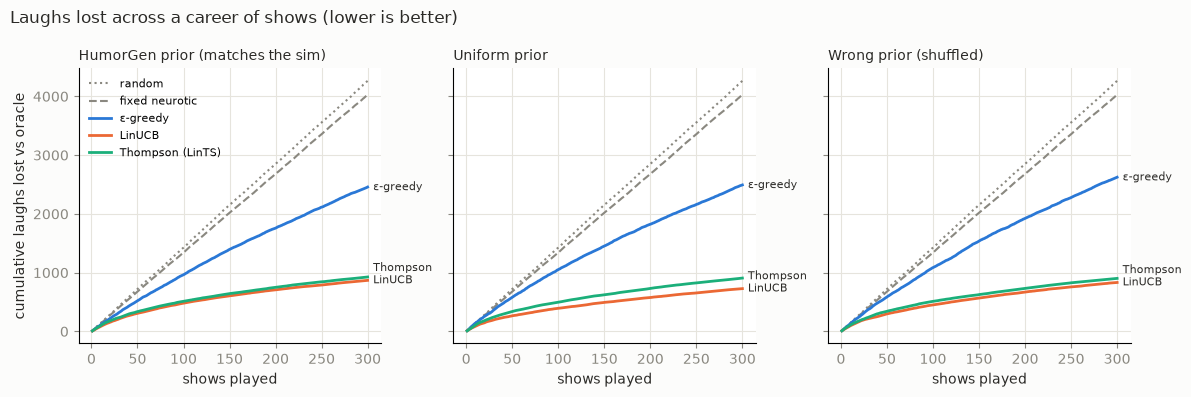

In [7]:
pol = run_or_load("policies", evaluate_policies.run, rerun=RERUN, shows=300, seeds=10)
show(evaluate_policies.table(pol))
fig = evaluate_policies.plot(pol)

In [8]:
lin, eps = pol["LinUCB | uniform"], pol["ε-greedy | uniform"]
neu, orc = pol["fixed neurotic"], pol["oracle"]
check(f"Experienced LinUCB gets ≥ 95% of the oracle ({lin['warm'][0] / orc['warm'][0]:.0%})",
      lin["warm"][0] / orc["warm"][0] >= 0.95)
check(f"LinUCB beats always-Neurotic by ≥ 15% once experienced (+{lin['warm'][0] / neu['warm'][0] - 1:.0%})",
      lin["warm"][0] / neu["warm"][0] >= 1.15)
check(f"Pooling matters: ε-greedy loses ≥ 2× more laughs ({eps['lost_total'][0] / lin['lost_total'][0]:.1f}×)",
      eps["lost_total"][0] >= 2 * lin["lost_total"][0])
lo = lambda r: r["lost_total"][0] - r["lost_total"][1]
hi = lambda r: r["lost_total"][0] + r["lost_total"][1]
lins = [pol[f"LinUCB | {p}"] for p in ("humorgen", "uniform", "wrong")]
check("The prior makes no significant difference for LinUCB (CIs overlap)", max(map(lo, lins)) <= min(map(hi, lins)))
check("Uniform has the lowest loss among LinUCB priors", min(lins, key=lambda r: r["lost_total"][0]) is lins[1])

✅ **Experienced LinUCB gets ≥ 95% of the oracle (97%)**

✅ **LinUCB beats always-Neurotic by ≥ 15% once experienced (+18%)**

✅ **Pooling matters: ε-greedy loses ≥ 2× more laughs (3.4×)**

✅ **The prior makes no significant difference for LinUCB (CIs overlap)**

✅ **Uniform has the lowest loss among LinUCB priors**

True

## Exp 5 Mid-set preference shift (2026-10-28)

**Decision:** keep the director's features; reacting within a show needs show state (MDP), not a
per-bit reaction feature.
**Where it fits:** can the director notice a room *turning*? ([simulated audience](../docs/wiki/simulated-audience.md))
**Options:** LinUCB / LinTS with and without the **reaction feature** (same mode × last reward).

**How to read:** in a random half of shows the room's taste shifts after bit `shift_at`.
"% of oracle" in **shifted** vs **steady** shows = what the turn costs. **Bits to recover**:
lower is better; compare with **random**: near it means recovering by luck, not by noticing.

In [9]:
sh = run_or_load("shift", evaluate_shift.run, rerun=RERUN, shows=400, seeds=10, shift_at=4)
show(evaluate_shift.table(sh))

| Policy | Shifted shows: after shift | % of oracle | Bits to recover | Steady shows: same bits | % of oracle |
|---|---|---|---|---|---|
| oracle | 24.0 ± 0.4 | 100% | 0.00 ± 0.00 | 23.7 ± 0.6 | 100% |
| fixed neurotic | 18.1 ± 0.4 | 75% | 3.69 ± 0.09 | 18.7 ± 0.6 | 79% |
| random | 17.6 ± 0.6 | 73% | 2.33 ± 0.10 | 18.8 ± 0.6 | 79% |
| LinUCB | 19.1 ± 0.6 | 80% | 2.46 ± 0.22 | 22.6 ± 0.7 | 95% |
| LinUCB + react | 19.5 ± 0.4 | 81% | 2.26 ± 0.28 | 22.6 ± 0.6 | 95% |
| LinTS | 19.7 ± 0.4 | 82% | 2.12 ± 0.13 | 22.8 ± 0.6 | 96% |
| LinTS + react | 19.9 ± 0.4 | 83% | 2.18 ± 0.15 | 22.8 ± 0.6 | 96% |

In [10]:
pct = lambda name, kind: sh[name][kind]["post"][0] / sh["oracle"][kind]["post"][0]
check(f"Steady shows: LinUCB ≥ 93% of oracle ({pct('LinUCB', 'steady'):.0%})", pct("LinUCB", "steady") >= 0.93)
check(f"Shifted shows: LinUCB drops below 85% ({pct('LinUCB', 'shifted'):.0%})", pct("LinUCB", "shifted") < 0.85)
rec = lambda n: sh[n]["shifted"]["recover"]
check("Learners recover no faster than random (within 0.3 bits)",
      all(rec(n)[0] > rec("random")[0] - 0.3 for n in ("LinUCB", "LinTS")))
gain = sh["LinUCB + react"]["shifted"]["post"][0] - sh["LinUCB"]["shifted"]["post"][0]
noise = sh["LinUCB + react"]["shifted"]["post"][1] + sh["LinUCB"]["shifted"]["post"][1]
check(f"Reaction feature gain ({gain:+.1f} laughs) is within noise (±{noise:.1f})", abs(gain) <= noise)

✅ **Steady shows: LinUCB ≥ 93% of oracle (95%)**

✅ **Shifted shows: LinUCB drops below 85% (80%)**

✅ **Learners recover no faster than random (within 0.3 bits)**

✅ **Reaction feature gain (+0.4 laughs) is within noise (±1.0)**

True

## Exp 6 Does a longer set let the director read a turn? (2026-10-28)

**Decision:** keep 8-bit sets (a 10-minute show); longer sets don't fix within-show adaptation.
**Where it fits:** follow-up to Exp 5. After the shift the director had only 4 bits left, so maybe it
just ran out of time? ([simulated audience](../docs/wiki/simulated-audience.md))
**Question:** with more bits after the shift, does the director climb back to its steady-show level?
**Options:** sets of 8, 16, 32, 52 bits (52 = a full hour special; Bargatze has 52), shift at the
midpoint. **Every career gets the same 3,200 bits of experience**, so longer sets mean fewer
shows, not more data. Evaluated on the last quarter of each career.

**How to read:** *choice quality* = expected reward of the chosen mode ÷ the best mode's (1.0 = best
pick). It's noise-free, so it shows *decisions*, not luck. In the figure, solid = shows where the room
turned, dotted = steady shows. If the director reads the room, the solid line climbs back to the
dotted one after the shift. **Bits to recover** is shown for comparison but is misleading here:
random "recovers" fast by luck, and a deterministic policy that sticks to its favorite looks worse.

| Set length (bits) | Shows per career | Policy | After shift: % of oracle laughs | Choice quality: first 2 bits after shift | Last quarter of set | Same bits, steady shows | Bits to recover (max) |
|---|---|---|---|---|---|---|---|
| 8 | 400 | random | 73% | 0.691 | 0.694 | 0.723 | 2.3 (4) |
| 8 | 400 | LinUCB | 80% | 0.771 | 0.768 | 0.930 | 2.5 (4) |
| 8 | 400 | LinTS | 82% | 0.788 | 0.787 | 0.939 | 2.1 (4) |
| 16 | 200 | random | 75% | 0.707 | 0.701 | 0.708 | 3.5 (8) |
| 16 | 200 | LinUCB | 81% | 0.762 | 0.778 | 0.936 | 4.6 (8) |
| 16 | 200 | LinTS | 82% | 0.772 | 0.786 | 0.943 | 4.1 (8) |
| 32 | 100 | random | 75% | 0.678 | 0.700 | 0.714 | 4.1 (16) |
| 32 | 100 | LinUCB | 80% | 0.720 | 0.767 | 0.936 | 10.1 (16) |
| 32 | 100 | LinTS | 84% | 0.777 | 0.785 | 0.939 | 6.0 (16) |
| 52 | 61 | random | 77% | 0.723 | 0.707 | 0.721 | 4.4 (26) |
| 52 | 61 | LinUCB | 82% | 0.731 | 0.812 | 0.931 | 14.1 (26) |
| 52 | 61 | LinTS | 85% | 0.777 | 0.809 | 0.939 | 7.8 (26) |

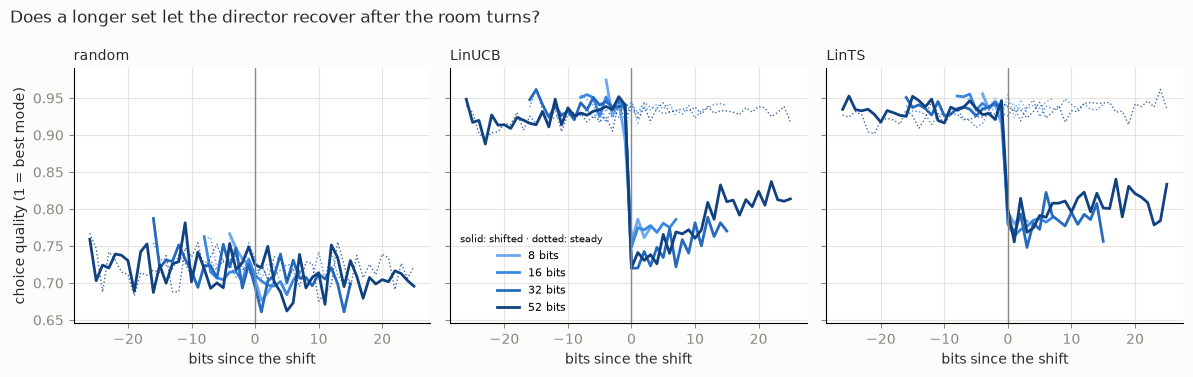

In [11]:
lengths = run_or_load("shift_set_length", evaluate_shift.run_lengths, rerun=RERUN,
                      lengths=[8, 16, 32, 52], total_bits=3200, seeds=10)
show(evaluate_shift.table_lengths(lengths))
fig = evaluate_shift.plot_lengths(lengths)

In [12]:
import numpy as np
def late(n, name, key="curve"):
    c, k = lengths[str(n)][key][name], int(n)
    return float(np.mean(c[k - max(1, k // 4):]))
def just_after(n, name):
    r = lengths[str(n)]
    return float(np.mean(r["curve"][name][r["shift_at"]:r["shift_at"] + 2]))
pct = lambda n, name: lengths[str(n)]["summary"][name]["shifted"]["post"][0] / lengths[str(n)]["summary"]["oracle"]["shifted"]["post"][0]

check("Even 26 bits after the shift, LinUCB's choices stay ≥ 0.1 below its steady-show level (all lengths)",
      all(late(n, "LinUCB", "steady_curve") - late(n, "LinUCB") >= 0.1 for n in (8, 16, 32, 52)))
check(f"Longer sets barely help: after-shift laughs go {pct(8, 'LinUCB'):.0%} → {pct(52, 'LinUCB'):.0%} of oracle (< 5 points)",
      pct(52, "LinUCB") - pct(8, "LinUCB") < 0.05)
check(f"It does drift back slowly: 52-bit LinUCB climbs {just_after(52, 'LinUCB'):.2f} → {late(52, 'LinUCB'):.2f} (≥ 0.05)",
      late(52, "LinUCB") - just_after(52, "LinUCB") >= 0.05)
rec = lambda n, name: lengths[str(n)]["summary"][name]["shifted"]["recover"][0]
check("'Bits to recover' misleads: deterministic LinUCB looks worse than random at 32+ bits",
      all(rec(n, "LinUCB") > rec(n, "random") for n in (32, 52)))

✅ **Even 26 bits after the shift, LinUCB's choices stay ≥ 0.1 below its steady-show level (all lengths)**

✅ **Longer sets barely help: after-shift laughs go 80% → 82% of oracle (< 5 points)**

✅ **It does drift back slowly: 52-bit LinUCB climbs 0.73 → 0.81 (≥ 0.05)**

✅ **'Bits to recover' misleads: deterministic LinUCB looks worse than random at 32+ bits**

True

## Adding a new decision

1. Put the experiment in a module as `run(**params) -> dict` and `table(results) -> str`
   (plus `plot` if it has a figure), and call it via `run_or_load(name, run, **params)`.
2. Add a section here: **Decision · Where it fits · Question/options · How to read**, a cell that
   runs it, and **checks** for every claim the decision makes.
3. Add the title fragment to `EVIDENCE` in the index cell, and the entry to `docs/decisions.md`.
4. `python scripts/run_notebook.py`, then commit the notebook with its outputs.